# 03 · Tyre degradation model

Plots and tables only. The model, fitting and evaluation code is in
`f1strat.deg_model`; the spec is `docs/model.md`.

Fits are loaded from `models/`. Rebuild them with
`uv run python -m f1strat.deg_model all`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from f1strat.clean import clean_laps
from f1strat.data import load_season
from f1strat.deg_model import (
    FULL_FIT_PATH, SPLITS, comparison_table, deg_by_race, deg_curve, effects_table,
    fit_xgboost, load_fit, predict, predict_baseline, fit_baseline, predict_xgboost,
    prepare, season_deg_table, split_fit_path, team_compound_summary,
)

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

COMPOUND_COLORS = {"SOFT": "#d9342b", "MEDIUM": "#eda100", "HARD": "#2a78d6"}
MODEL_COLORS = {"Baseline (OLS)": "#52514e", "XGBoost": "#eb6834", "Bayesian": "#2a78d6"}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "savefig.dpi": 150, "savefig.bbox": "tight",
})

laps = prepare(clean_laps(load_season(2022)))
full = load_fit(FULL_FIT_PATH)
split_fits = {name: load_fit(split_fit_path(name)) for name in SPLITS}
event = laps.groupby("RoundNumber")["EventName"].first().str.replace(" Grand Prix", "")
for name, f in {"full": full, **split_fits}.items():
    print(name, f.diagnostics)

full {'max_r_hat': 1.0097478421319448, 'min_ess_bulk': 689.0959585764391, 'min_ess_tail': 1115.5569689977353, 'divergences': 0}
last_stint {'max_r_hat': 1.005187120025507, 'min_ess_bulk': 810.7753626420842, 'min_ess_tail': 1308.1377515265422, 'divergences': 0}
long_tyre {'max_r_hat': 1.004431956215465, 'min_ess_bulk': 1365.7220115243074, 'min_ess_tail': 1882.7735950313352, 'divergences': 0}


## Model comparison on the held-out sets

In [2]:
comp = comparison_table(laps, split_fits)
comp.to_csv(FIG_DIR / "model_comparison.csv", index=False)
comp.round(3)

,split,subset,model,mae_s,rmse_s,n_predicted,n_unpredictable,coverage_80
0,last_stint,common,baseline,1.238,4.685,5542,0,NaN
1,last_stint,common,xgboost,0.819,1.064,5542,0,NaN
2,last_stint,common,bayes,0.578,0.832,5542,0,0.679
3,last_stint,all,xgboost,0.822,1.070,5618,0,NaN
4,last_stint,all,bayes,0.585,0.849,5618,0,0.681
5,long_tyre,common,baseline,0.524,0.742,5539,0,NaN
6,long_tyre,common,xgboost,0.510,0.760,5539,0,NaN
7,long_tyre,common,bayes,0.531,0.741,5539,0,0.702
8,long_tyre,all,xgboost,0.510,0.760,5539,0,NaN
9,long_tyre,all,bayes,0.531,0.741,5539,0,0.702


## Season degradation rate per compound

Field-average car. `deg` is the linear rate; `cliff` the curvature; the loss
columns combine both after 10 and 20 laps of tyre age. 80% intervals.

In [3]:
season = season_deg_table(full)
season.to_csv(FIG_DIR / "season_deg.csv", index=False)

def fmt(m, lo, hi, nd=3):
    return f"{m:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"

table = pd.DataFrame({
    "Compound": season["compound"].str.title(),
    "Deg (s/lap)": [fmt(*r) for r in season[["deg_s_per_lap", "deg_s_per_lap_lo", "deg_s_per_lap_hi"]].to_numpy()],
    "Cliff (s/lap²)": [fmt(*r, nd=5) for r in season[["cliff_s_per_lap2", "cliff_s_per_lap2_lo", "cliff_s_per_lap2_hi"]].to_numpy()],
    "Loss after 10 laps (s)": [fmt(*r, nd=2) for r in season[["loss_10_laps_s", "loss_10_laps_s_lo", "loss_10_laps_s_hi"]].to_numpy()],
    "Loss after 20 laps (s)": [fmt(*r, nd=2) for r in season[["loss_20_laps_s", "loss_20_laps_s_lo", "loss_20_laps_s_hi"]].to_numpy()],
})
(FIG_DIR / "season_deg.md").write_text(table.to_markdown(index=False) + "\n")
table

,Compound,Deg (s/lap),Cliff (s/lap²),Loss after 10 laps (s),Loss after 20 laps (s)
0,Soft,"0.091 [0.067, 0.115]","0.00026 [0.00001, 0.00052]","0.94 [0.70, 1.17]","1.92 [1.47, 2.39]"
1,Medium,"0.076 [0.062, 0.091]","-0.00009 [-0.00020, 0.00002]","0.75 [0.61, 0.90]","1.49 [1.20, 1.78]"
2,Hard,"0.051 [0.036, 0.067]","0.00010 [0.00003, 0.00018]","0.52 [0.37, 0.68]","1.07 [0.76, 1.38]"


In [4]:
effects = effects_table(full)
effects.round(4)

,effect,level,unit,mean,lo,hi
0,mu_deg,SOFT,s/lap,0.0910,0.0671,0.1150
1,mu_deg,MEDIUM,s/lap,0.0762,0.0616,0.0910
2,mu_deg,HARD,s/lap,0.0512,0.0357,0.0671
3,cliff,SOFT,s/lap^2,0.0003,0.0000,0.0005
4,cliff,MEDIUM,s/lap^2,-0.0001,-0.0002,0.0000
5,cliff,HARD,s/lap^2,0.0001,0.0000,0.0002
6,mu_compound,SOFT,s,-0.3783,-0.5049,-0.2535
7,mu_compound,HARD,s,0.3890,0.2651,0.5118
8,warmup,SOFT,s,-0.0278,-0.0844,0.0285
9,warmup,MEDIUM,s,-0.0666,-0.1063,-0.0270


## Degradation curves per compound, with 80% bands

Tyre effect alone (compound offset + deg + cliff) for the field-average car,
relative to a new medium. Fuel and track trend are not included. Each curve is
drawn up to the oldest tyre age run on that compound at that race.

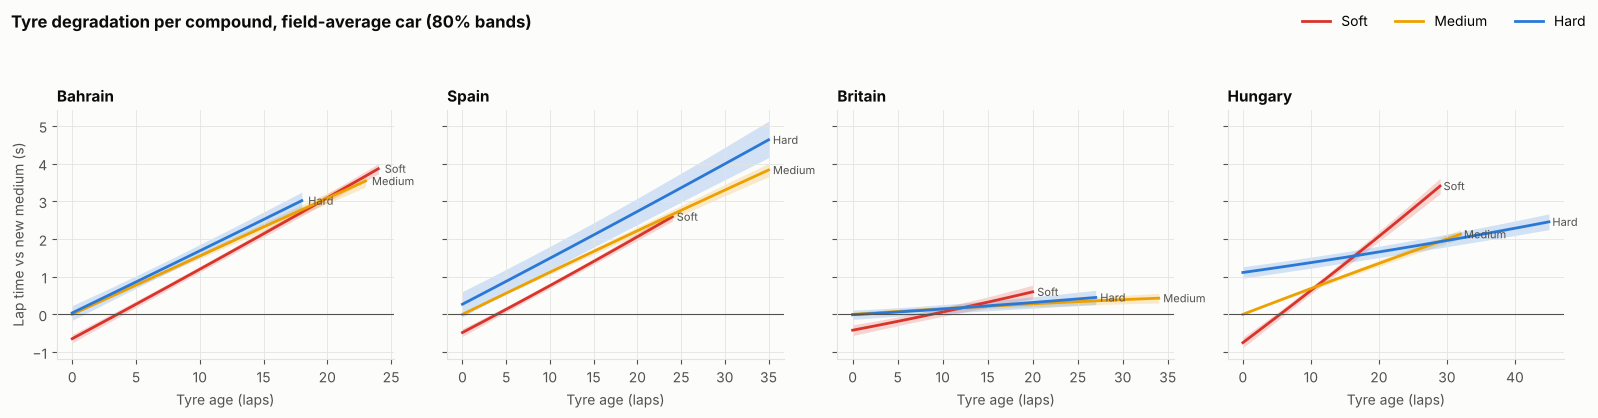

In [5]:
races = [(1, "Bahrain"), (6, "Spain"), (10, "Britain"), (13, "Hungary")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
for ax, (rnd, name) in zip(axes, races):
    race_laps = laps[laps["RoundNumber"] == rnd]
    for comp, color in COMPOUND_COLORS.items():
        used = race_laps.loc[race_laps["Compound"] == comp, "TyreLife"]
        if used.empty:
            continue
        curve = deg_curve(full, rnd, comp, np.arange(0, used.max() + 1))
        ax.fill_between(curve["TyreLife"], curve["lo"], curve["hi"], color=color, alpha=0.2, linewidth=0)
        ax.plot(curve["TyreLife"], curve["mean"], color=color, linewidth=2, label=comp.title())
        ax.text(curve["TyreLife"].iloc[-1] + 0.5, curve["mean"].iloc[-1], comp.title(),
                color=INK_2, fontsize=8, va="center")
    ax.axhline(0, color=INK_2, linewidth=0.8)
    ax.set_title(name, loc="left")
    ax.set_xlabel("Tyre age (laps)")
axes[0].set_ylabel("Lap time vs new medium (s)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=3, frameon=False)
fig.suptitle("Tyre degradation per compound, field-average car (80% bands)", x=0.01, ha="left",
             fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(FIG_DIR / "deg_curves.png")
plt.show()

## Extrapolation: XGBoost vs Bayesian vs actual on `long_tyre`

Both models are trained only on tyre age ≤ 15 laps. Left: mean signed error by
tyre age (positive = predicted too slow). Right: one long stint, actual laps vs
both models.

/tmp/ipykernel_2765/1205279933.py:18: PerformanceWarning: indexing past lexsort depth may impact performance.
  stint = test.set_index(stint_key).loc[longest].reset_index()


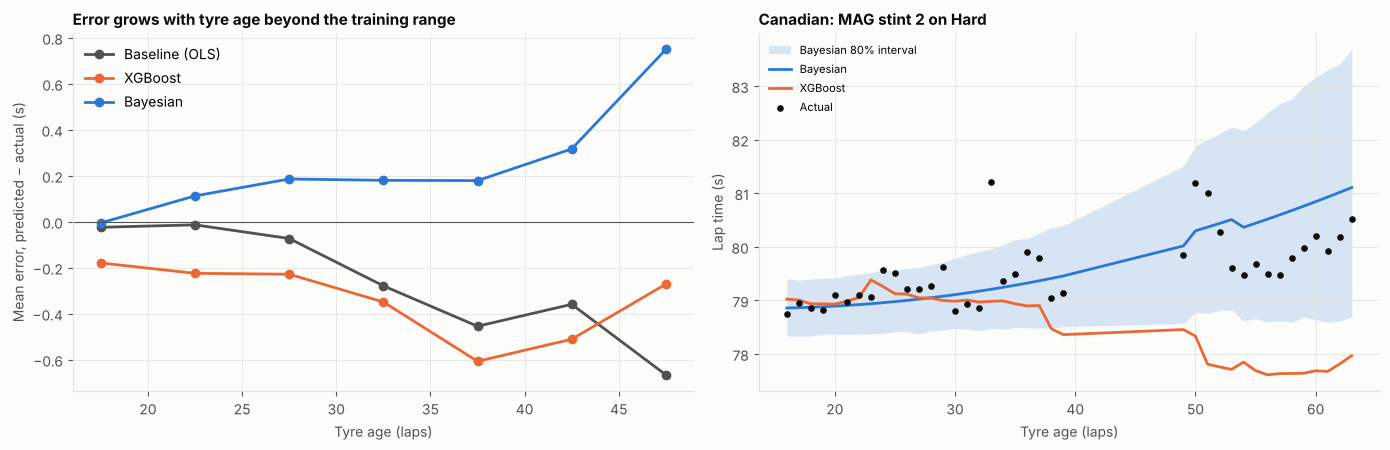

,Baseline (OLS),XGBoost,Bayesian
TyreLife,,,
"(15, 20]",-0.024,-0.179,-0.005
"(20, 25]",-0.013,-0.224,0.113
"(25, 30]",-0.073,-0.228,0.186
"(30, 35]",-0.279,-0.349,0.180
"(35, 40]",-0.454,-0.607,0.179
"(40, 45]",-0.359,-0.511,0.317
"(45, 50]",-0.666,-0.271,0.750


In [6]:
train, test = SPLITS["long_tyre"](laps)
xgb_pred = predict_xgboost(fit_xgboost(train), test)
bayes_pred = predict(split_fits["long_tyre"], test)
base_pred = predict_baseline(fit_baseline(train), test)

bins = np.arange(15, 51, 5)
age_bin = pd.cut(test["TyreLife"], bins)
err = pd.DataFrame({
    "Baseline (OLS)": base_pred - test["lap_s"],
    "XGBoost": xgb_pred - test["lap_s"],
    "Bayesian": bayes_pred.mean - test["lap_s"],
}).groupby(age_bin, observed=True).mean()
mids = [iv.mid for iv in err.index]

# Longest single stint in the test set, for the right panel.
stint_key = ["RoundNumber", "Driver", "Stint"]
longest = test.groupby(stint_key)["TyreLife"].max().idxmax()
stint = test.set_index(stint_key).loc[longest].reset_index()
idx = test.index[(test[stint_key] == pd.Series(longest, index=stint_key)).all(axis=1)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
for model, color in MODEL_COLORS.items():
    ax1.plot(mids, err[model], marker="o", color=color, linewidth=2, label=model)
ax1.axhline(0, color=INK_2, linewidth=0.8)
ax1.set_xlabel("Tyre age (laps)")
ax1.set_ylabel("Mean error, predicted − actual (s)")
ax1.set_title("Error grows with tyre age beyond the training range", loc="left")
ax1.legend(frameon=False)

x = test.loc[idx, "TyreLife"]
ax2.fill_between(x, bayes_pred.lo[idx], bayes_pred.hi[idx], color=MODEL_COLORS["Bayesian"], alpha=0.18,
                 linewidth=0, label="Bayesian 80% interval")
ax2.plot(x, bayes_pred.mean[idx], color=MODEL_COLORS["Bayesian"], linewidth=2, label="Bayesian")
ax2.plot(x, xgb_pred[idx], color=MODEL_COLORS["XGBoost"], linewidth=2, label="XGBoost")
ax2.scatter(x, test.loc[idx, "lap_s"], color=INK, s=14, zorder=3, label="Actual")
rnd, drv, st = longest
ax2.set_title(f"{event[rnd]}: {drv} stint {st} on {stint['Compound'].iloc[0].title()}", loc="left")
ax2.set_xlabel("Tyre age (laps)")
ax2.set_ylabel("Lap time (s)")
ax2.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "xgb_vs_bayes_long_tyre.png")
plt.show()
err.round(3)

## Leclerc, Hungary 2022: hard stint, laps 41–53

Full-data fit, so these laps are in the training data: this checks fit, not
forecasting. Dots are actual laps; the line and band are the model's mean and
80% prediction interval.

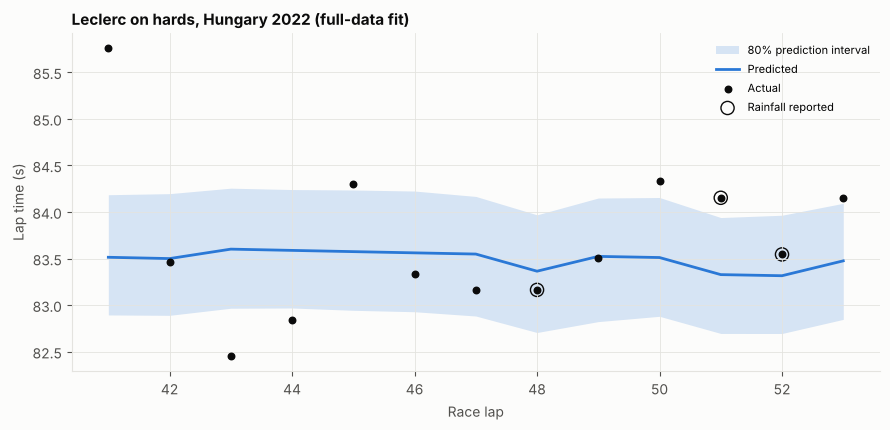

,lap,TyreLife,actual,predicted,lo,hi
8349,41,2,85.755,83.513,82.894,84.185
8350,42,3,83.462,83.499,82.890,84.196
8351,43,4,82.456,83.601,82.966,84.255
8352,44,5,82.839,83.587,82.969,84.240
8353,45,6,84.300,83.574,82.944,84.236
8354,46,7,83.335,83.561,82.929,84.224
8355,47,8,83.158,83.548,82.883,84.167
8356,48,9,83.163,83.364,82.706,83.969
8357,49,10,83.509,83.523,82.823,84.150
8358,50,11,84.334,83.511,82.880,84.155


In [7]:
lec = laps[(laps["RoundNumber"] == 13) & (laps["Driver"] == "LEC") & laps["race_lap"].between(41, 53)]
lec_pred = predict(full, lec)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.fill_between(lec["race_lap"], lec_pred.lo, lec_pred.hi, color=COMPOUND_COLORS["HARD"], alpha=0.18,
                linewidth=0, label="80% prediction interval")
ax.plot(lec["race_lap"], lec_pred.mean, color=COMPOUND_COLORS["HARD"], linewidth=2, label="Predicted")
ax.scatter(lec["race_lap"], lec["lap_s"], color=INK, s=22, zorder=3, label="Actual")
rain = lec[lec["Rainfall"]]
ax.scatter(rain["race_lap"], rain["lap_s"], facecolors="none", edgecolors=INK, s=90, linewidths=1,
           label="Rainfall reported")
ax.set_xlabel("Race lap")
ax.set_ylabel("Lap time (s)")
ax.set_title("Leclerc on hards, Hungary 2022 (full-data fit)", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "leclerc_hungary_hard.png")
plt.show()
pd.DataFrame({"lap": lec["race_lap"], "TyreLife": lec["TyreLife"], "actual": lec["lap_s"],
              "predicted": lec_pred.mean, "lo": lec_pred.lo, "hi": lec_pred.hi}).round(3)

## Ferrari's compound terms at Hungary (full data)

Reported only; interpreted in Phase 6. `team_compound` is Ferrari's deviation
from the field at this race (medium = 0), `field_compound` the field's offset,
`total` their sum, and `team_deg_s_per_lap` Ferrari's season deg vs the field.

In [8]:
team_compound_summary(full, "Ferrari", 13).round(3)

,team,RoundNumber,compound,term,mean,lo,hi
0,Ferrari,13,SOFT,team_compound,0.193,0.056,0.330
1,Ferrari,13,SOFT,field_compound,-0.750,-0.886,-0.612
2,Ferrari,13,SOFT,total,-0.557,-0.740,-0.377
3,Ferrari,13,SOFT,team_deg_s_per_lap,0.007,0.002,0.011
4,Ferrari,13,MEDIUM,team_compound,0.000,0.000,0.000
5,Ferrari,13,MEDIUM,field_compound,0.000,0.000,0.000
6,Ferrari,13,MEDIUM,total,0.000,0.000,0.000
7,Ferrari,13,MEDIUM,team_deg_s_per_lap,0.007,0.005,0.010
8,Ferrari,13,HARD,team_compound,0.307,0.111,0.510
9,Ferrari,13,HARD,field_compound,1.111,0.958,1.265


## Flags: hard degrading faster than soft, or negative degradation

Field-average linear deg per race and compound (s/lap). Flagged, not forced.

In [9]:
flags = deg_by_race(full).assign(Event=lambda d: d["RoundNumber"].map(event))
flagged = flags[flags["negative"] | flags["hard_faster_than_soft"]]
flagged.round(3)

,RoundNumber,compound,mean,lo,hi,p_negative,p_hard_gt_soft,negative,hard_faster_than_soft,Event
5,2,HARD,-0.004,-0.010,0.002,0.799,0.067,True,False,Saudi Arabian
8,3,HARD,-0.010,-0.016,-0.004,0.982,0.063,True,False,Australian
11,5,HARD,-0.000,-0.005,0.004,0.546,0.418,True,False,Miami
48,21,SOFT,0.040,0.031,0.050,0.000,0.981,False,True,São Paulo
49,21,MEDIUM,0.070,0.065,0.075,0.000,0.981,False,True,São Paulo
50,21,HARD,0.103,0.066,0.140,0.001,0.981,False,True,São Paulo
